# Homework 2: A Forecast for VELTRAXA

**Relapsed/refractory mantle cell lymphoma**

**Applied Data Science and AI in Pharma Commercial · Columbia University · Fall 2026**

@Author: Michael Chen (mwc2150) 

---

## a. The brief

VELTRAXA is a fictional once-daily oral BTK degrader launching in July 2027 for relapsed/refractory mantle cell lymphoma after at least one prior line (2L+). The brand forecaster needs:

- a monthly budget for July 2027 to December 2028;
- a long-range plan to 2035, with a low, base and high case;
- an answer to one question: the plan of record says **$180M in 2029**. Is that reachable, and what would have to be true?

Use the model from class. Grading rewards clear, well-supported assumptions, not model complexity. All data are synthetic.

## b. Data (`data/homework2/`)

| File | Use |
|---|---|
| `mcl_epi_inputs.csv` | New MCL cases per year (sum the age bands) |
| `mcl_treatment_funnel.csv` | Diagnosed, treated and progression rates, with ranges |
| `mcl_market_monthly.csv` | Observed 2L and 3L+ starts, 2019–2026, to check your funnel |
| `mcl_market_by_region.csv` | Regional shares for the top-down split |
| `mcl_analog_launches_monthly.csv`, `mcl_analog_launches_attributes.csv` | Six analog launches: peak share and uptake by year |
| `veltraxa_assumptions.csv` | Starter assumption book: launch, price, gross-to-net, compliance, patent expiry |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from pathlib import Path
warnings.filterwarnings("ignore"); pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 70)
NAVY, CORAL, ICE, GREY, TEAL, GOLD = "#1E2761", "#FF6B6B", "#CADCFC", "#888888", "#2A9D8F", "#E8B04B"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
DATA = next((p for p in [Path("data"), Path("../data"), Path(".")] if (p / "veltraxa_assumptions.csv").exists()), Path("."))

# Our own image folder: created next to the notebook if it doesn't exist
IMG = Path("img")
IMG.mkdir(exist_ok=True)
def savefig(name):
    plt.savefig(IMG / name, bbox_inches="tight", dpi=150)

# 1. Assumption Book
    At least 20 rows in the class format (ID, category, assumption, unit, low, base, high, source type, source, reason). Every number in the model traces to a row. Support the key rows with the data: progression rates from the funnel file, peak share and uptake from the analogs and the order-of-entry rule, months on therapy from the label and analogs.

**Thought process.** Revenue is a chain of multiplications, and every term in the chain is a row in the book. Two questions need data:

1. **How many patients are there at each line?** (`mcl_epi_inputs.csv`, `mcl_treatment_funnel.csv`) How many people get MCL, and of those, how many reach each line of treatment?
2. **How much of that does VELTRAXA win?** (`mcl_analog_launches_attributes.csv`, `mcl_analog_launches_monthly.csv`) What peak share and uptake do comparable launches reach?

Terms with no data behind them (months on therapy, coverage, phasing) are judgments, and the book labels them as such.

In [2]:
# Q1: how many patients reach each line?
epi = pd.read_csv(DATA / "mcl_epi_inputs.csv")
fun = pd.read_csv(DATA / "mcl_treatment_funnel.csv")

cases = epi.groupby("year").incident_cases.sum()
growth = (cases[2030] / cases[2025]) ** (1 / 5) - 1            # case growth, used after the file ends in 2030

# the funnel file is by age band: weight each band by its share of 2025 new cases
w = epi[epi.year == 2025].set_index("age_band").incident_cases
fun = fun.merge((w / w.sum()).rename("w"), left_on="age_band", right_index=True)
rates = fun[["low", "base", "high"]].mul(fun.w, axis=0).groupby(fun.parameter).sum()
rates

,low,base,high
parameter,,,
diagnosed_and_presenting,0.949276,0.969276,0.979276
later_lines_multiplier,1.141409,1.261409,1.381409
progress_to_2L_treated,0.485024,0.545024,0.605024
progress_to_3L_treated,0.426427,0.506427,0.586427
treated_1L,0.847188,0.887188,0.917188


In [3]:
# Q2: how much does VELTRAXA win?
an = pd.read_csv(DATA / "mcl_analog_launches_monthly.csv")
at = pd.read_csv(DATA / "mcl_analog_launches_attributes.csv").set_index("analog")
s = an.pivot(index="month_since_launch", columns="analog", values="share_of_line_starts")

at["peak"] = s.tail(6).mean()                                   # peak share = average of the last 6 months
# uptake as % of peak, by calendar year: a July 2027 launch has months 1-6 in 2027, 7-18 in 2028, 19-30 in 2029
for u, (a, b) in {"U1": (1, 6), "U2": (7, 18), "U3": (19, 30)}.items():
    at[u] = (s.loc[a:b].sum() / 12 / at.peak).clip(upper=1)

# order-of-entry rule: fit log(peak) on order for the three 2L+ BTK inhibitors, read off a 4th entrant
btk = at[at.line == "2L+"]
slope, icpt = np.polyfit(btk.order_in_class, np.log(btk.peak), 1)
peak_4th = np.exp(icpt + 4 * slope)

print(f"4th entrant peak share: {peak_4th:.1%}")
at[["line", "order_in_class", "peak", "U1", "U2", "U3"]].round(3)

4th entrant peak share: 15.4%


,line,order_in_class,peak,U1,U2,U3
analog,,,,,,
"BTKi A (first in class, 2L+ MCL)",2L+,1,0.441,0.033,0.481,0.948
"BTKi B (second, more selective)",2L+,2,0.296,0.039,0.606,1.000
BTKi C (third),2L+,3,0.221,0.032,0.606,1.000
"CAR-T (MCL, 3L+)",3L+,1,0.178,0.015,0.255,0.778
Non-covalent BTKi (post-BTKi),3L+,4,0.283,0.043,0.663,0.977
"Bispecific (3L+ MCL, off-label use)",3L+,1,0.121,0.035,0.496,0.935


In [4]:
# The book: the 5 starter rows + one line per new row. Values come from the two cells above; judgments are typed in.
r, oral, l3 = rates.loc, at[at.drug_class == "BTK inhibitor"], at[at.line == "3L+"]
span = lambda x, base: (x.min(), base, x.max())                 # low = worst analog, high = best analog

rows = [
    # id, category, assumption, unit, low, base, high, source_type, source, rationale
    ("E0", "Epidemiology", "Incidence scaler", "x", 0.95, 1.0, 1.05, "Judgment", "-", "+/-5% for registry error"),
    ("E1", "Epidemiology", "Case growth after 2030", "%/yr", growth - 0.01, growth, growth + 0.01, "Data", "mcl_epi_inputs.csv", "2025-2030 trend; +/-1 pt"),
    ("E2", "Funnel", "Diagnosed and presenting", "%", *r["diagnosed_and_presenting"], "Data", "mcl_treatment_funnel.csv", "Age bands weighted by 2025 cases"),
    ("T1", "Funnel", "Treated in 1L", "%", *r["treated_1L"], "Data", "mcl_treatment_funnel.csv", "Age bands weighted by 2025 cases"),
    ("T2", "Funnel", "Progress 1L to 2L", "%", *r["progress_to_2L_treated"], "Data", "mcl_treatment_funnel.csv", "Age bands weighted by 2025 cases"),
    ("T3", "Funnel", "Progress 2L to 3L", "%", *r["progress_to_3L_treated"], "Data", "mcl_treatment_funnel.csv", "Age bands weighted by 2025 cases"),
    ("T4", "Funnel", "Later-lines multiplier", "x", *r["later_lines_multiplier"], "Data", "mcl_treatment_funnel.csv", "3L+ includes 4L and later"),
    ("T5", "Funnel", "Lag between lines", "years", 1, 1, 1, "Judgment", "Class model", "Next line starts the following year"),
    ("B2", "Brand", "Launch year in 2L", "year", 2027, 2027, 2027, "Regulatory plan", "Brief", "2L+ label: 2L and 3L+ launch together"),
    ("B3", "Brand", "Peak share, 3L+", "% of starts", *span(l3.peak, l3.peak.mean()), "Analog", "Analog files", "Mean of the 3L+ analogs"),
    ("B4", "Brand", "Peak share, 2L", "% of starts", at.peak.min(), peak_4th, btk.peak.min(), "Analog", "Analog files", "Order-of-entry fit, 4th entrant; high = 3rd entrant"),
    ("U1", "Uptake", "% of peak, 2027", "% of peak", *span(at.U1, oral.U1.mean()), "Analog", "Analog files", "July launch: 6 months; base = oral BTKi mean"),
    ("U2", "Uptake", "% of peak, 2028", "% of peak", *span(at.U2, oral.U2.mean()), "Analog", "Analog files", "Base = oral BTKi mean"),
    ("U3", "Uptake", "% of peak, 2029", "% of peak", *span(at.U3, oral.U3.mean()), "Analog", "Analog files", "Base = oral BTKi mean"),
    ("U4", "Uptake", "% of peak, 2030+", "% of peak", 1, 1, 1, "Analog", "Analog files", "All analogs at peak by month 31"),
    ("C1", "Brand", "Coverage, launch year", "x", 0.75, 0.9, 1.0, "Judgment", "-", "Launch-year formulary friction"),
    ("C2", "Brand", "Coverage, after launch year", "x", 0.95, 1.0, 1.0, "Judgment", "-", "Analog shares already include access"),
    ("D1", "Persistence", "Months on therapy (booked in start year)", "28-day months", 10, 14, 18, "Judgment", "Brief", "Taken until progression; no duration data"),
    ("D2", "Persistence", "Compliance (doses taken)", "% of planned", 0.85, 0.90, 0.94, "Judgment", "Oral therapy adherence", "Starter value kept; once-daily oral, so some doses are missed; range spans better or worse adherence"),
    ("P2", "Price", "Gross-to-net (share of WAC kept)", "%", 0.70, 0.75, 0.79, "Judgment", "Part D + commercial mix", "Starter value kept; net price after Part D and commercial rebates; range spans payer-mix uncertainty"),
    ("L1", "LOE", "Loss-of-exclusivity year", "year", 2040, 2041, 2042, "Patent calendar", "Fictional", "Starter value kept; +/-1 year for patent extension or litigation; after 2035, so no effect on the plan"),
    ("L2", "LOE", "Units retained, LOE year", "%", 0.50, 0.62, 0.75, "Benchmark", "Week 6 notebook", "After 2035; kept for completeness"),
    ("L3", "LOE", "Units retained, after LOE year", "%", 0.15, 0.23, 0.35, "Benchmark", "Grabowski et al. 2021", "Small-molecule erosion"),
    ("F1", "Budget", "Launch-year phasing: linear ramp over Jul-Dec 2027 (month m proportional to m)", "months", 6, 6, 6, "Simplification", "Class model", "Annual total unchanged; weights 1..6 / 21"),
    ("F2", "Budget", "Phasing after launch year: flat (1/12 per month)", "months", 12, 12, 12, "Simplification", "Class model", "Annual total unchanged; overstates early 2028, understates late 2028"),

]
cols = ["id", "category", "assumption", "unit", "low", "base", "high", "source_type", "source", "rationale"]
starter = pd.read_csv(DATA / "veltraxa_assumptions.csv")[cols]
starter = starter[~starter.id.isin([row[0] for row in rows])]   # D2, P2, L1 are re-stated above with a rationale; keep the other starter rows
book = pd.concat([starter, pd.DataFrame(rows, columns=cols)])
book[["low", "base", "high"]] = book[["low", "base", "high"]].astype(float).round(3)
book = book.sort_values("id", ignore_index=True)
book.to_csv("HW2_mwc2150_assumptions.csv", index=False)
book

,id,category,assumption,unit,low,base,high,source_type,source,rationale
0,B1,Brand,Launch year (2L+ relapsed/refractory MCL),year,2027.000,2027.000,2027.000,Regulatory plan,PDUFA July 2027 (fictional),Launch mid-year: year-1 uptake should reflect ~6 months on market
1,B2,Brand,Launch year in 2L,year,2027.000,2027.000,2027.000,Regulatory plan,Brief,2L+ label: 2L and 3L+ launch together
2,B3,Brand,"Peak share, 3L+",% of starts,0.121,0.194,0.283,Analog,Analog files,Mean of the 3L+ analogs
3,B4,Brand,"Peak share, 2L",% of starts,0.121,0.154,0.221,Analog,Analog files,"Order-of-entry fit, 4th entrant; high = 3rd entrant"
4,C1,Brand,"Coverage, launch year",x,0.750,0.900,1.000,Judgment,-,Launch-year formulary friction
5,C2,Brand,"Coverage, after launch year",x,0.950,1.000,1.000,Judgment,-,Analog shares already include access
6,D1,Persistence,Months on therapy (booked in start year),28-day months,10.000,14.000,18.000,Judgment,Brief,Taken until progression; no duration data
7,D2,Persistence,Compliance (doses taken),% of planned,0.850,0.900,0.940,Judgment,Oral therapy adherence,"Starter value kept; once-daily oral, so some doses are missed; ran..."
8,E0,Epidemiology,Incidence scaler,x,0.950,1.000,1.050,Judgment,-,+/-5% for registry error
9,E1,Epidemiology,Case growth after 2030,%/yr,0.016,0.026,0.036,Data,mcl_epi_inputs.csv,2025-2030 trend; +/-1 pt


# 2. Funnel and brand forecast 
    Annual, 2023–2035: new cases, 1L, 2L and 3L+ starts, new VELTRAXA patients, patients on therapy, net revenue. State the model type (incidence or prevalence; flow or stock). Show that the funnel matches the 2025 market within about 10%, or explain the gap.

In [5]:
# value of every book row under a scenario; swing = {id: "low"/"high"} moves single rows (used for the tornado in section 3)
def assumptions(scn="base", swing={}):
    b = book.set_index("id")
    return {k: b.loc[k, swing.get(k, scn)] for k in b.index}
v = assumptions()

def funnel(v):
    years = range(2021, 2036)              # 2021-2035; 2021-22 only feed the one-year lags and are dropped below
    f = pd.DataFrame(index=years)
    f["cases"] = [cases.get(y, cases[2030] * (1 + v["E1"]) ** (y - 2030)) * v["E0"] for y in years]   # file to 2030, then E1 growth
    f["treated_1L"] = f.cases * v["E2"] * v["T1"]
    f["starts_2L"] = f.treated_1L.shift(1) * v["T2"]              # one-year lag (T5)
    f["starts_3Lplus"] = f.starts_2L.shift(1) * v["T3"] * v["T4"]
    return f.loc[2023:]                    # 2023-26 = market history (for the 2025 check), 2027-35 = forecast
f = funnel(v); f.round(0)

,cases,treated_1L,starts_2L,starts_3Lplus
2023,2748.0,2362.0,1255.0,781.0
2024,2817.0,2421.0,1287.0,801.0
2025,2888.0,2482.0,1320.0,821.0
2026,2964.0,2548.0,1353.0,842.0
2027,3040.0,2613.0,1388.0,863.0
2028,3119.0,2681.0,1424.0,886.0
2029,3200.0,2750.0,1461.0,909.0
2030,3284.0,2823.0,1499.0,932.0
2031,3369.0,2896.0,1538.0,956.0
2032,3457.0,2971.0,1578.0,982.0


In [6]:
def brand(v):
    f = funnel(v); out = pd.DataFrame(index=f.index)
    def share(peak, launch):
        s = []
        for y in f.index:
            k = int(y - launch + 1)                      # 2027 = year 1 (6 months, U1), 2028 = U2, 2029 = U3, 2030+ = U4
            if k < 1: s.append(0.0); continue            # 2023-26: not launched yet
            uptake = [v["U1"], v["U2"], v["U3"], v["U4"]][min(k, 4) - 1]
            coverage = v["C1"] if k == 1 else v["C2"]
            loe = 1.0 if y < v["L1"] else (v["L2"] if y == v["L1"] else v["L3"])   # LOE 2041: no effect before 2035
            s.append(peak * uptake * coverage * loe)
        return pd.Series(s, index=f.index)
    out["new_3Lplus"] = f.starts_3Lplus * share(v["B3"], v["B1"])
    out["new_2L"] = f.starts_2L * share(v["B4"], v["B2"])
    out["new_patients"] = out.new_3Lplus + out.new_2L
    out["on_therapy_avg"] = out.new_patients * v["D1"] * 28 / 365
    out["net_revenue_musd"] = out.new_patients * v["D1"] * v["D2"] * v["P1"] * v["P2"] / 1e6
    return f.join(out)                                   # one table: funnel + brand, 2023-2035
lrp = brand(v)
print(f"2029: ${lrp.loc[2029, 'net_revenue_musd']:.0f}M (plan of record: $180M)")
lrp.round(1)


2029: $62M (plan of record: $180M)


,cases,treated_1L,starts_2L,starts_3Lplus,new_3Lplus,new_2L,new_patients,on_therapy_avg,net_revenue_musd
2023,2748.0,2361.9,1254.9,781.3,0.0,0.0,0.0,0.0,0.0
2024,2817.0,2421.2,1287.2,800.7,0.0,0.0,0.0,0.0,0.0
2025,2888.0,2482.2,1319.6,821.3,0.0,0.0,0.0,0.0,0.0
2026,2964.0,2547.6,1352.8,842.0,0.0,0.0,0.0,0.0,0.0
2027,3040.0,2612.9,1388.4,863.2,5.6,7.1,12.7,13.6,2.0
2028,3119.0,2680.8,1424.0,885.9,101.2,129.2,230.4,247.4,36.6
2029,3200.0,2750.4,1461.0,908.6,172.9,220.7,393.6,422.8,62.5
2030,3284.0,2822.6,1499.0,932.2,180.9,230.8,411.7,442.1,65.4
2031,3369.4,2896.0,1538.3,956.4,185.6,236.9,422.5,453.7,67.1
2032,3457.0,2971.3,1578.3,981.6,190.4,243.1,433.5,465.5,68.8


In [7]:
# BUDGET: the same model's 2027-28 annual values, phased by month (F1: linear ramp over Jul-Dec 2027; F2: flat in 2028)
months = []
for y, n in [(2027, int(v["F1"])), (2028, int(v["F2"]))]:
    w = [m / sum(range(1, n + 1)) for m in range(1, n + 1)] if y == v["B1"] else [1 / n] * n   # ramp weights 1..6 / 21, or flat 1/12
    for i in range(n):
                months.append(dict(month=f"{y}-{13 - n + i:02d}",                                     # launch year starts in July
                           new_patients=lrp.loc[y, "new_patients"] * w[i],
                           on_therapy=lrp.loc[y, "on_therapy_avg"] * 12 * w[i],                 # as in class: monthly values average to the annual figure
                           net_revenue_musd=lrp.loc[y, "net_revenue_musd"] * w[i]))
bud = pd.DataFrame(months)
print("check, sums match the annual plan:", bud.groupby(bud.month.str[:4]).net_revenue_musd.sum().round(1).tolist(), "vs", lrp.loc[[2027, 2028], "net_revenue_musd"].round(1).tolist())
bud.round(1)

check, sums match the annual plan: [2.0, 36.6] vs [2.0, 36.6]


,month,new_patients,on_therapy,net_revenue_musd
0,2027-07,0.6,7.8,0.1
1,2027-08,1.2,15.6,0.2
2,2027-09,1.8,23.4,0.3
3,2027-10,2.4,31.2,0.4
4,2027-11,3.0,39.0,0.5
5,2027-12,3.6,46.8,0.6
6,2028-01,19.2,247.4,3.0
7,2028-02,19.2,247.4,3.0
8,2028-03,19.2,247.4,3.0
9,2028-04,19.2,247.4,3.0


Model Type:
- incidence-based (new diagnoses / MCL cases each year)
- flow model (treatment lines w/1 year lag from 1L up to 3L+) 

In [8]:
# 2025 check: does the funnel reproduce the observed market?
mk = pd.read_csv(DATA / "mcl_market_monthly.csv")
obs = mk.groupby(mk.month.str[:4].astype(int))[["starts_2L", "starts_3Lplus"]].sum()
check = pd.DataFrame({"observed": obs.loc[2025], "funnel": f.loc[2025, ["starts_2L", "starts_3Lplus"]]})
check["gap"] = (check.funnel / check.observed - 1).map("{:+.0%}".format)
check.round(0)

,observed,funnel,gap
starts_2L,1279.0,1320.0,+3%
starts_3Lplus,864.0,821.0,-5%


# 3.	Ranges 
    Low, base and high scenarios, and a tornado chart for 2029 revenue. Name the three assumptions that matter most.

       low  base   high
2025   0.0   0.0    0.0
2026   0.0   0.0    0.0
2027   0.0   2.0    7.0
2028   5.0  37.0  115.0
2029  15.0  62.0  177.0
2030  20.0  65.0  182.0
2031  21.0  67.0  187.0
2032  21.0  69.0  193.0
2033  21.0  71.0  200.0
2034  22.0  72.0  207.0
2035  22.0  74.0  214.0
2029: low $15M · base $62M · high $177M (plan of record: $180M)


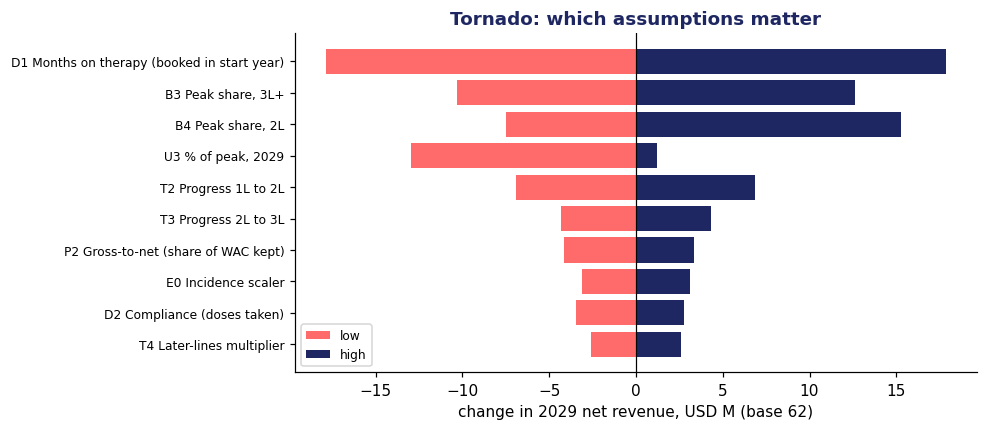

Top three assumptions: D1 Months on therapy (booked in start year), B3 Peak share, 3L+, B4 Peak share, 2L


In [9]:
# Scenarios: every assumption at its low, base or high together
sc = pd.DataFrame({s: brand(assumptions(s)).net_revenue_musd for s in ["low", "base", "high"]})
print(sc.loc[2025:].round(0).to_string())
print(f"2029: low ${sc.loc[2029, 'low']:.0f}M · base ${sc.loc[2029, 'base']:.0f}M · high ${sc.loc[2029, 'high']:.0f}M (plan of record: $180M)")

# Tornado: move one assumption at a time to its low and high; rows with no effect (fixed values, LOE after 2035) drop out
YEAR = 2029; base = sc.loc[YEAR, "base"]; bars = []
for _, r in book.iterrows():
    lo, hi = brand(assumptions(swing={r.id: "low"})).loc[YEAR, "net_revenue_musd"], brand(assumptions(swing={r.id: "high"})).loc[YEAR, "net_revenue_musd"]
    if abs(hi - lo) > 1e-6: bars.append(dict(assumption=f"{r.id} {r.assumption}", low=lo - base, high=hi - base))
tor = pd.DataFrame(bars).assign(swing=lambda d: (d.high - d.low).abs()).sort_values("swing").tail(10)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(tor.assumption, tor.low, color=CORAL, label="low"); ax.barh(tor.assumption, tor.high, color=NAVY, label="high"); ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel(f"change in {YEAR} net revenue, USD M (base {base:.0f})"); ax.legend(fontsize=8); ax.set_title("Tornado: which assumptions matter", color=NAVY, fontweight="bold"); ax.tick_params(axis="y", labelsize=8)
savefig("tornado.png"); plt.show()
print("Top three assumptions:", ", ".join(tor.assumption.iloc[::-1][:3]))


# 4.	Checks 
    Compare a simple trend of 2L+ starts with your funnel for 2027–28. Split 2028 new patients by region so the regions sum to the national total.

In [10]:
# Trend check: a straight line through annual 2L+ starts (2019-2025, full years), extended to 2027-28
hist = obs.loc[2019:2025].sum(axis=1)                       # obs = annual observed starts, from the 2025 check cell
line = np.poly1d(np.polyfit(hist.index, hist.values, 1))
trend = pd.DataFrame({"trend": line([2027, 2028]), "funnel": (f.starts_2L + f.starts_3Lplus).loc[[2027, 2028]].values}, index=[2027, 2028])
trend["gap"] = (trend.funnel / trend.trend - 1).map("{:+.0%}".format)
trend.round(0)

,trend,funnel,gap
2027,2175.0,2252.0,+4%
2028,2218.0,2310.0,+4%


In [11]:
# Regional split of 2028 new patients (top-down, as in class): each line is split by its regional share of
# starts in the latest 12 months of data (Jul 2025-Jun 2026), assuming that mix holds through 2028
reg = pd.read_csv(DATA / "mcl_market_by_region.csv")
share = reg[reg.month >= "2025-07"].pivot_table(index="region", columns="line", values="treatment_starts", aggfunc="sum")
share = share / share.sum()
print("Regional share of starts, Jul 2025-Jun 2026:"); print(share.round(3))

split = pd.DataFrame({"new_2L": share["2L"] * lrp.loc[2028, "new_2L"], "new_3Lplus": share["3Lplus"] * lrp.loc[2028, "new_3Lplus"]})
split["new_patients_2028"] = split.sum(axis=1)
print(f"\nregions sum to {split.new_patients_2028.sum():.1f} = national {lrp.loc[2028, 'new_patients']:.1f}")
split.round(1)


Regional share of starts, Jul 2025-Jun 2026:
line          2L  3Lplus
region                  
Midwest    0.248   0.198
Northeast  0.162   0.198
South      0.378   0.394
West       0.212   0.210

regions sum to 230.4 = national 230.4


,new_2L,new_3Lplus,new_patients_2028
region,,,
Midwest,32.0,20.0,52.0
Northeast,20.9,20.1,41.0
South,48.9,39.9,88.7
West,27.4,21.3,48.7


# 5.	Memo 
    Two pages to the brand forecaster: the forecast and its range in one chart; the three key assumptions and the evidence that would change each; your answer on $180M; what you would research in the next 90 days. Include the monthly budget and the annual long-range plan from the same model, with the phasing assumption stated.

Summary: $180M in 2029 is not reachable based on the current evidence. Even with every assumption held true in the high case, the forecast predicts that the net revenue of $180M is really only achievable from 2030 onwards (hits $177M in 2029). However, in the low or base case, the highest the net revenue goes is ~$20M and ~$70M respectively. See the forecast and its range in one chart below (based off the numbers presented in Section 3: Ranges):


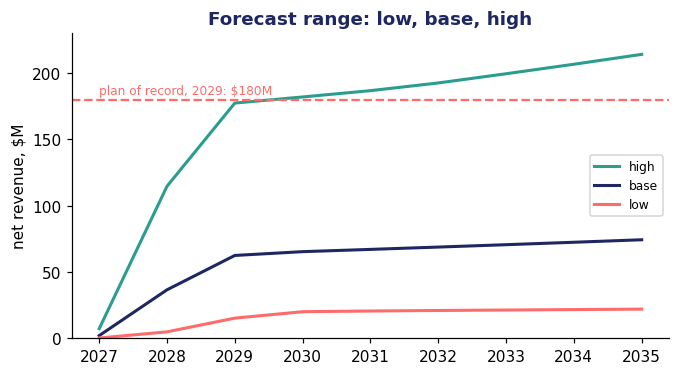

In [12]:
# The forecast and its range in one chart 
fig, ax = plt.subplots(figsize=(7, 3.6))
for s, c in [("high", TEAL), ("base", NAVY), ("low", CORAL)]: ax.plot(sc.loc[2027:].index, sc.loc[2027:, s], color=c, lw=2, label=s)
ax.axhline(180, color=CORAL, ls="--"); ax.text(2027, 184, "plan of record, 2029: $180M", color=CORAL, fontsize=8)
ax.set_ylim(0, 230); ax.set_ylabel("net revenue, $M"); ax.legend(fontsize=8); ax.set_title("Forecast range: low, base, high", color=NAVY, fontweight="bold")
savefig("forecast_range.png"); plt.show()

Three key assumptions driving our forecast/ranges (from the Section 3 Tornado): 
1. D1 Months on therapy (booked in start year)
2. B3 Peak share, 3L+
3. B4 Peak share, 2L

Given the above context, reaching $180M seems difficult unless we can substantiate that each of the three assumptions are going to held in the years following launch in 2027. In the next 90 days, researching into each of the 3 assumptions below-- duration-on-therapy data for D1 & PA/Payer/Competitor landscape for B3 and B4-- would help identify whether the plan of record is achievable. 

Evidence that would change each assumption:
1. We would need RWE on the time of treatment from EMR data, medical claims, trial data for Veltraxa, or even info on Rx refills. The more months here that can be proven, the better the revenue forecast.
2. For this, we would need to see prescription rates for patients who progressed on a BTK inhibitor or how competitors in 3L+ are doing as a relative proxy to adjust for. Stated use or interest will be strong, positive signals. 
3. As the 4th drug in the BTK class, we would want to see the formulary positioning of Veltraxa or do some PA outreach (look into payer/prior-auth) to see if they would reccomend this over other established inhibitors. Requirements to try some class of this drug will account for the volume of treatment being pushed out. 


Below is the monthly budget and the annual long-range plan from the same model. For the monthly budget, new patients rise to ~13 in total, for roughly $2M of revenue in 2027. In the 2028, about 230 new patients adds $36.6M or ~$3M a month. The long range plan all the way through 2035 supports our conclusion above on the unlikeliness that the plan of record will be attainable. 
- Phasing assumption: There's a linear ramp in the launch year (builds month by month from July - December 2027) and then it becomes flat afterwards (each month in 2028 gets the same amount). Flat phasing jumps revenue from $0.6M in December 2027 to $3.0M a month, which will obviously overstate the revenue from early in the year and then understate the revenue from later in teh year since the actual on-therapy count would build gradually.

      new_patients_base  revenue_low  revenue_base  revenue_high
2027               13.0          0.0           2.0           7.0
2028              230.0          5.0          37.0         115.0
2029              394.0         15.0          62.0         177.0
2030              412.0         20.0          65.0         182.0
2031              422.0         21.0          67.0         187.0
2032              433.0         21.0          69.0         193.0
2033              445.0         21.0          71.0         200.0
2034              456.0         22.0          72.0         207.0
2035              468.0         22.0          74.0         214.0


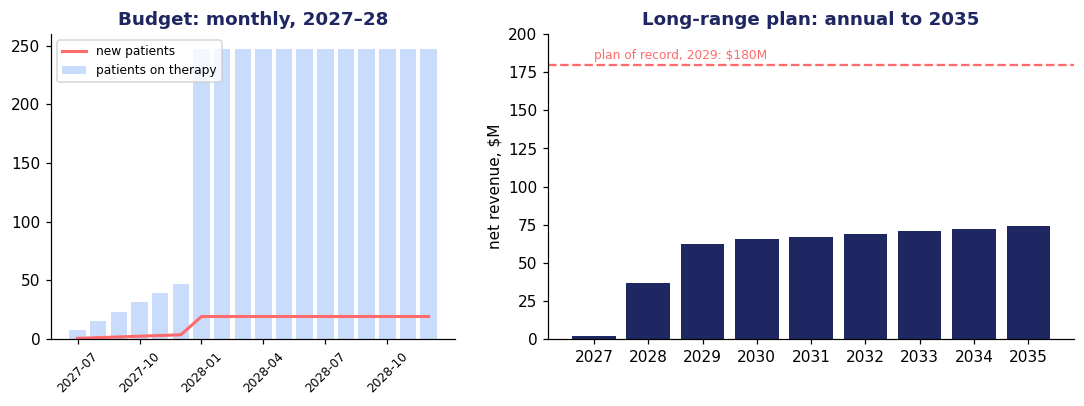

In [13]:
# LONG-RANGE PLAN (annual, 2027-2035): base new patients and net revenue in the low / base / high cases
plan = pd.DataFrame({"new_patients_base": lrp.new_patients, "revenue_low": sc.low, "revenue_base": sc.base, "revenue_high": sc.high}).loc[2027:]
print(plan.round(0).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
ax[0].bar(bud.month, bud.on_therapy, color=ICE, label="patients on therapy"); ax[0].plot(bud.month, bud.new_patients, color=CORAL, lw=2, label="new patients")
ax[0].set_xticks(bud.month[::3]); ax[0].tick_params(axis="x", rotation=45, labelsize=8); ax[0].legend(fontsize=8); ax[0].set_title("Budget: monthly, 2027–28", color=NAVY, fontweight="bold")
ax[1].bar(plan.index, plan.revenue_base, color=NAVY); ax[1].axhline(180, color=CORAL, ls="--"); ax[1].text(2027, 184, "plan of record, 2029: $180M", color=CORAL, fontsize=8)
ax[1].set_xticks(plan.index); ax[1].set_ylim(0, 200); ax[1].set_ylabel("net revenue, $M"); ax[1].set_title("Long-range plan: annual to 2035", color=NAVY, fontweight="bold")
savefig("budget_lrp.png"); plt.show()

---

## AI usage disclosure

Claude (Claude Code in VS Code) was used to review this notebook and the other deliverables after they were written, and to set up the GitHub repository and README. The review covered re-executing the notebook from a clean copy, which reproduced the saved outputs and the assumption book exactly, and checking the deliverables against the assignment requirements. Claude did not change the analysis, the assumptions, the figures or the memo text during that review.